# 01 · Baseline evaluation (pretrained models, no training)

**Question:** how good are YOLO models that were *never trained on our data*? Their score is the bar our fine-tuned model has to beat.

We test two pretrained models on the same test images:
- **COCO `yolov8n`**: general model, has dog / cat / cow / sheep but **no goat**.
- **Open Images V7 `yolov8m-oiv7`**: has all five of our animals. Caution: our test images come from Open Images, so this model may have seen them in training, and its score is probably too optimistic.

Each pretrained model uses its own class numbers, so the notebook translates them to our five classes
(0 dog, 1 goat, 2 cow, 3 cat, 4 sheep) and then runs the standard Ultralytics validation.

By default the notebook runs on **10 images** so it finishes in about a minute. Set `FULL_RUN = True` for all 80 test images.

## 1. Find the project and set the parameters

In [1]:
# Find the project root (the folder that contains PROJECT_PLAN.md) and work from there,
# so every path below is relative to the project root no matter where Jupyter was started.
import os, sys
from pathlib import Path

here = Path.cwd().resolve()
for folder in [here, *here.parents]:
    if (folder / "PROJECT_PLAN.md").exists():
        os.chdir(folder)
        break
else:
    raise SystemExit("PROJECT_PLAN.md not found: start Jupyter inside the project folder")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))   # lets us import small helpers from src/ if we need them
print("project root:", ROOT)

project root: /home/upicy/comp_vision


In [2]:
# ---- parameters: change things here ----
FULL_RUN = False                       # False: 10 images (fast demo). True: whole test split (80 images).
SPLIT = "test"                         # which split of the dataset to evaluate
MAX_IMAGES = None if FULL_RUN else 10
DATA_YAML = "data/dataset/data.yaml"
IMGSZ = 640                            # image size the model sees
COCO_WEIGHTS = "yolov8n.pt"            # COCO baseline (downloaded automatically if missing)
OIV7_WEIGHTS = "yolov8m-oiv7.pt"       # Open Images V7 baseline (already in the project root)
SAVE_CSV = False                       # True: overwrite results/baseline.csv (only sensible together with FULL_RUN=True)

import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| images:", MAX_IMAGES or "all")

device: 0 | images: 10


## 2. Translate the baselines' classes into ours
A pretrained model predicts class numbers from *its* list (COCO has 80, Open Images has 601). We keep only the five animals
we care about and rename them to our ids. Everything else the model predicts is ignored.
Goat does not exist in COCO, so for that model goat is marked "not supported" (AP stays empty instead of a misleading 0).

In [3]:
from IPython.display import display
import pandas as pd

COCO_MAP = {16: 0, 19: 2, 15: 3, 18: 4}           # COCO id -> our id : dog, cow, cat, sheep   (no goat)
OIV7_MAP = {160: 0, 219: 1, 99: 2, 96: 3, 452: 4}  # Open Images id -> our id : Dog, Goat, Cattle, Cat, Sheep

mapping = pd.DataFrame({
    "our class": ["0 dog", "1 goat", "2 cow", "3 cat", "4 sheep"],
    "COCO yolov8n": ["16 dog", "NOT SUPPORTED", "19 cow", "15 cat", "18 sheep"],
    "Open Images yolov8m": ["160 Dog", "219 Goat", "99 Cattle", "96 Cat", "452 Sheep"]})
display(mapping)

,our class,COCO yolov8n,Open Images yolov8m
0,0 dog,16 dog,160 Dog
1,1 goat,NOT SUPPORTED,219 Goat
2,2 cow,19 cow,99 Cattle
3,3 cat,15 cat,96 Cat
4,4 sheep,18 sheep,452 Sheep


## 3. Load the test images and their labels

In [4]:
import yaml

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
cfg = yaml.safe_load(Path(DATA_YAML).read_text())
NAMES = {int(k): v for k, v in cfg["names"].items()}            # our classes: 0 dog, 1 goat, 2 cow, 3 cat, 4 sheep

def list_images(split):
    """All image files of a split, e.g. data/dataset/images/test/*.jpg (sorted, so runs are repeatable)."""
    folder = Path(cfg["path"]) / cfg[split]
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXT)

def label_file(img):
    """The YOLO label file of an image: .../images/test/a.jpg -> .../labels/test/a.txt"""
    return Path(str(img).replace("/images/", "/labels/")).with_suffix(".txt")

images = list_images(SPLIT)[:MAX_IMAGES]                         # [:None] keeps everything
n_boxes = sum(len([l for l in label_file(i).read_text().splitlines() if l.strip()]) for i in images if label_file(i).exists())
print(f"{len(images)} images from split '{SPLIT}', {n_boxes} labelled boxes")

10 images from split 'test', 22 labelled boxes


## 4. Evaluation code
`build_tmp_dataset` writes a throw-away copy of the test set whose label numbers match the model being tested
(images are only linked, nothing is copied). Then the official `model.val` computes precision, recall, mAP and per-class AP.
FPS is measured separately by timing `model.predict` image by image.

- **mAP50**: share of animals found with a box overlapping the true box by at least 50%, averaged over classes.
- **mAP50-95**: the same but with stricter overlap limits (50% to 95%). Always lower; rewards tight boxes.

In [5]:
import shutil, time
import numpy as np
import pandas as pd
from ultralytics import YOLO

TMP = ROOT / "runs/notebooks/_eval_tmp"            # scratch dataset, rebuilt on every evaluation (runs/ is git-ignored)

def build_tmp_dataset(imgs, cls_map):
    """Copy-free dataset for the official validator: symlink the images and write their labels using the MODEL's class ids.
    cls_map = {model_class_id: our_class_id}. Boxes of classes the model cannot predict are dropped (their AP becomes NaN).
    cls_map=None means the model already uses our ids."""
    inverse = {ours: theirs for theirs, ours in cls_map.items()} if cls_map else None
    shutil.rmtree(TMP, ignore_errors=True)
    (TMP / "images/test").mkdir(parents=True); (TMP / "labels/test").mkdir(parents=True)
    for img in imgs:
        (TMP / "images/test" / img.name).symlink_to(img.resolve())
        lines = []
        if label_file(img).exists():
            for line in label_file(img).read_text().splitlines():
                parts = line.split()
                if not parts:
                    continue
                ours = int(float(parts[0]))
                if inverse is None:
                    lines.append(line)
                elif ours in inverse:
                    lines.append(" ".join([str(inverse[ours])] + parts[1:]))
        (TMP / "labels/test" / (img.stem + ".txt")).write_text("\n".join(lines) + ("\n" if lines else ""))

def evaluate_model(weights, imgs, cls_map=None, plots=False):
    """Official Ultralytics validation (conf 0.001, NMS IoU 0.7, batch 1) + FPS. Returns one row of metrics."""
    model = YOLO(str(weights))
    build_tmp_dataset(imgs, cls_map)
    (TMP / "data.yaml").write_text(yaml.safe_dump({"path": str(TMP), "train": "images/test", "val": "images/test",
                                                   "test": "images/test", "names": {int(k): v for k, v in model.names.items()}}))
    r = model.val(data=str(TMP / "data.yaml"), split="test", imgsz=IMGSZ, batch=1, conf=0.001, iou=0.7, device=DEVICE,
                  plots=plots, verbose=False, project=str(TMP / "val"), name="v", exist_ok=True, save=False)
    per_class = {}
    for k, cls_id in enumerate(r.box.ap_class_index):                      # AP50 of every class that has ground truth
        per_class[cls_map[int(cls_id)] if cls_map else int(cls_id)] = float(r.box.ap50[k])
    model.predict(str(imgs[0]), imgsz=IMGSZ, verbose=False, device=DEVICE)  # warm-up (first call is slow)
    t0 = time.perf_counter()
    for img in imgs:
        model.predict(str(img), imgsz=IMGSZ, conf=0.25, verbose=False, device=DEVICE)
    sec = (time.perf_counter() - t0) / len(imgs)
    row = {"images": len(imgs), "precision": float(r.box.mp), "recall": float(r.box.mr), "mAP50": float(r.box.map50),
           "mAP50-95": float(r.box.map), "FPS": 1 / sec}
    for cls_id, name in NAMES.items():
        row[f"AP50_{name}"] = per_class.get(cls_id, np.nan)                # NaN = no ground truth / not supported
    return row, r

## 5. Run both baselines

In [6]:
rows = []
for name, weights, cls_map in [("baseline_coco_yolov8n", COCO_WEIGHTS, COCO_MAP),
                               ("baseline_oiv7_yolov8m", OIV7_WEIGHTS, OIV7_MAP)]:
    row, _ = evaluate_model(weights, images, cls_map)
    rows.append({"model": name, **row})
    print("done:", name)
baseline = pd.DataFrame(rows)
baseline.round(3)

Ultralytics 8.4.213 🚀 Python-3.11.17 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5822MiB)


YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5252.9±672.3 MB/s, size: 456.2 KB)


val: Scanning /home/upicy/comp_vision/runs/notebooks/_eval_tmp/labels/test... 10 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.1Kit/s 0.0s

val: New cache created: /home/upicy/comp_vision/runs/notebooks/_eval_tmp/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10% ━─────────── 1/10 1.4it/s 0.2s<6.5s

... (11 outputs left out)

                   all         10         22      0.971      0.771      0.929      0.693


Speed: 0.4ms preprocess, 16.7ms inference, 0.0ms loss, 0.8ms postprocess per image


done: baseline_oiv7_yolov8m


,model,images,precision,recall,mAP50,mAP50-95,FPS,AP50_dog,AP50_goat,AP50_cow,AP50_cat,AP50_sheep
0,baseline_coco_yolov8n,10,0.887,0.633,0.838,0.690,92.945,0.828,NaN,0.848,NaN,NaN
1,baseline_oiv7_yolov8m,10,0.971,0.771,0.929,0.693,54.479,0.995,0.866,0.925,NaN,NaN


## 6. Chart the result

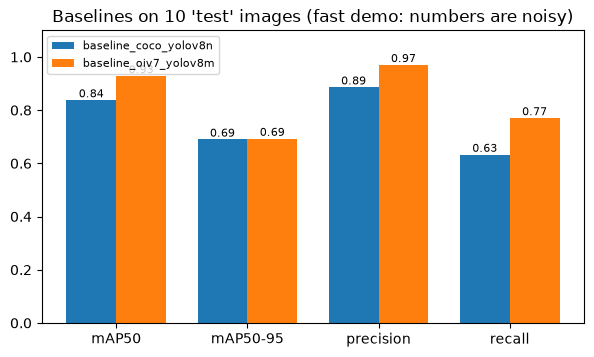

In [7]:
import matplotlib.pyplot as plt

metrics = ["mAP50", "mAP50-95", "precision", "recall"]
x = range(len(metrics))
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (_, r) in enumerate(baseline.iterrows()):
    bars = ax.bar([i + (k - 0.5) * 0.38 for i in x], [r[m] for m in metrics], 0.38, label=r["model"])
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(list(x), metrics); ax.set_ylim(0, 1.1); ax.legend(fontsize=8)
ax.set_title(f"Baselines on {len(images)} '{SPLIT}' images" + ("" if FULL_RUN else " (fast demo: numbers are noisy)"))
plt.show()

## 7. Compare with the saved full-run numbers
`results/baseline.csv` holds the official numbers on all 80 test images. The 10-image demo above will not match them exactly
because it sees fewer images; the full run (`FULL_RUN = True`) reproduces them.

In [8]:
saved = pd.read_csv("results/baseline.csv")
display(saved[["model", "images", "mAP50", "mAP50-95", "precision", "recall", "FPS"]].round(3))

if SAVE_CSV:
    baseline.to_csv("results/baseline.csv", index=False)
    print("results/baseline.csv overwritten")
else:
    print("SAVE_CSV is False: results/baseline.csv left untouched")

,model,images,mAP50,mAP50-95,precision,recall,FPS
0,baseline_coco_yolov8n,80,0.810,0.643,0.799,0.705,114.676
1,baseline_oiv7_yolov8m,80,0.906,0.765,0.794,0.885,55.863


SAVE_CSV is False: results/baseline.csv left untouched


## What to take away
- The Open Images model scores highest, but its test score is probably inflated (it was trained on Open Images).
- COCO cannot see goats at all, which is exactly why we fine-tune on our own five classes (notebook 02).